# IS630: Green Light for an Indie Studio
## Notebook 06: AQ5, How Does the Number of Player Reviews Affect the Reliability of Estimated Player Reception?
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> An AI coding assistant wrote the code in this notebook. The Beta-Binomial model, its priors and its posterior predictive statistics follow Sheen Fernando's reception model from the archived notebook 03, with the developer effects removed at the group's direction. The group must review and accept the model before submission. Every code section is labelled with its provenance. All interpretations, evaluations of model performance and conclusions are written by group members in the designated cells.

**AQ5** (group wording): *How does the number of player reviews affect the reliability of estimated player reception?*

Player reception is the Steam positive review rate, positive reviews over all reviews. A rate from 12 reviews and a rate from 12,000 are both reported as a single percentage, so this notebook measures how much each one can be trusted:

| Section | Content |
|---|---|
| 1 | The sample, and the sampling uncertainty of the raw rate (Wilson intervals) |
| 2 | Beta-Binomial model of reception |
| 3 | Posterior predictive check |
| 4 | Prior sensitivity |
| 5 | Shrinkage: how far each game's rate moves towards the model's expectation, by review count |
| 6 | Raw against shrunken rankings |
| 7 | Validation: calibration and interval coverage by review count |

**Reads:** `data/processed/02_train.parquet`, `data/processed/02_validation.parquet`, `data/processed/02_feature_spec.json`
**Writes:** `data/interim/06_aq5_shrinkage.parquet`, tables `outputs/tables/06_aq5_*.csv`, figures `outputs/figures/06_aq5_*.png`, traces in `outputs/models` (gitignored)

The validation set is the 20% split made in notebook 02 from training data. The test holdout from notebook 00 is never loaded here.

## Setup
*Code: Generated by AI Assistant*

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit
from statsmodels.stats.proportion import proportion_confint
import pymc as pm
import arviz as az

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config

for d in (config.FIGURES, config.TABLES, config.MODELS):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
rng = np.random.default_rng(config.SEED)

def save_fig(fig, name):
    # Write a figure to outputs/figures at 300 dpi.
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

df_train = pd.read_parquet(config.PROCESSED / "02_train.parquet")
df_val = pd.read_parquet(config.PROCESSED / "02_validation.parquet")
with open(config.PROCESSED / "02_feature_spec.json", encoding="utf-8") as f:
    feature_spec = json.load(f)
FEATURES = feature_spec["model_features"]
MIN_REVIEWS = feature_spec["inclusion_thresholds"]["min_reviews_reception"]
assert set(df_train["steam_appid"]).isdisjoint(df_val["steam_appid"])
print(f"rows in: {len(df_train):,} development training, {len(df_val):,} validation")
print(f"predictors from notebook 02: {len(FEATURES)}; reception threshold from notebook 02: {MIN_REVIEWS} reviews")
print(f"pymc {pm.__version__}, arviz {az.__version__}")

g++ not available, if using conda: `conda install gxx`


rows in: 4,224 development training, 1,057 validation
predictors from notebook 02: 31; reception threshold from notebook 02: 10 reviews
pymc 6.3.2, arviz 1.3.0


## 1. The sample and the uncertainty of the raw rate
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the sample is every game with `flag_reception_model`, the minimum review count fixed in notebook 02 and printed above. The raw positive rate is `steam_positive / steam_review_count`. Its 95% Wilson interval is the range of true rates consistent with that many reviews, treating each review as an independent draw. The table groups games into review-count bands. Review counts grow with a game's age and audience, so the bands also differ in those.

In [2]:
BANDS = [MIN_REVIEWS, 50, 200, 1000, 10000, np.inf]
BAND_LABELS = [f"{MIN_REVIEWS}-49", "50-199", "200-999", "1,000-9,999", "10,000+"]

def prepare(frame):
    out = frame[frame["flag_reception_model"]].copy()
    out["n"] = out["steam_review_count"].astype(int)
    out["k"] = out["steam_positive"].astype(int)
    assert (out["n"] == out["steam_positive"] + out["steam_negative"]).all()
    assert out["n"].ge(MIN_REVIEWS).all() and out["k"].le(out["n"]).all()
    out["raw_rate"] = out["k"] / out["n"]
    out["wilson_low"], out["wilson_high"] = proportion_confint(out["k"], out["n"], alpha=0.05, method="wilson")
    out["wilson_width"] = out["wilson_high"] - out["wilson_low"]
    out["band"] = pd.cut(out["n"], BANDS, labels=BAND_LABELS, right=False)
    return out

train, val = prepare(df_train), prepare(df_val)
print(f"rows out (reception sample): {len(train):,} train, {len(val):,} validation")

band_table = train.groupby("band", observed=True).agg(
    games=("n", "size"), median_reviews=("n", "median"), median_raw_rate=("raw_rate", "median"),
    sd_raw_rate=("raw_rate", "std"), median_wilson_width=("wilson_width", "median"))
band_table.to_csv(config.TABLES / "06_aq5_raw_rate_by_band.csv")
band_table.round(3)

rows out (reception sample): 4,115 train, 1,029 validation


,games,median_reviews,median_raw_rate,sd_raw_rate,median_wilson_width
band,,,,,
10-49,532,29.0,0.856,0.166,0.259
50-199,1007,106.0,0.846,0.140,0.135
200-999,1207,406.0,0.863,0.118,0.064
"1,000-9,999",993,2617.0,0.885,0.106,0.023
"10,000+",376,25103.0,0.913,0.093,0.007


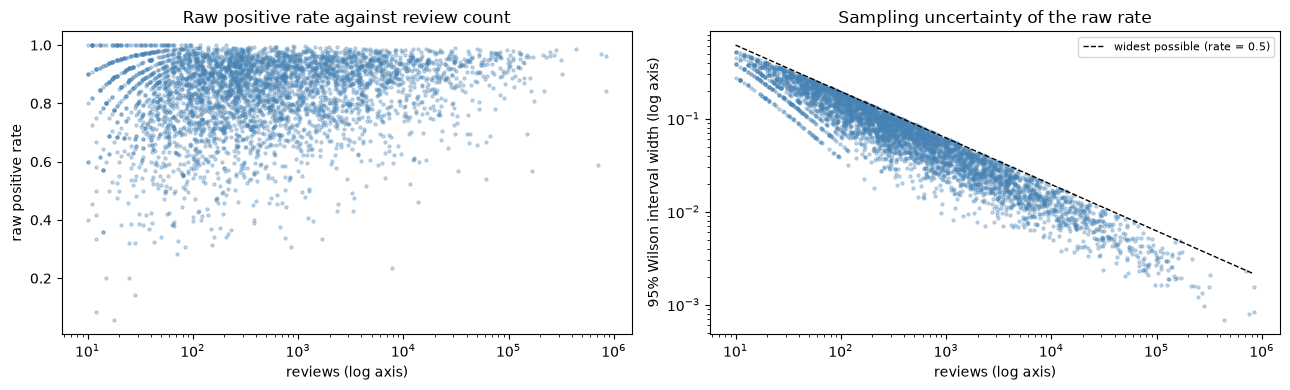

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(train["n"], train["raw_rate"], s=5, alpha=0.3, color="steelblue")
axes[0].set_xscale("log"); axes[0].set_xlabel("reviews (log axis)"); axes[0].set_ylabel("raw positive rate")
axes[0].set_title("Raw positive rate against review count")
axes[1].scatter(train["n"], train["wilson_width"], s=5, alpha=0.3, color="steelblue")
grid = np.logspace(np.log10(MIN_REVIEWS), np.log10(train["n"].max()), 100)
axes[1].plot(grid, 2 * 1.96 * np.sqrt(0.25 / grid), color="black", linestyle="--", linewidth=1, label="widest possible (rate = 0.5)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("reviews (log axis)"); axes[1].set_ylabel("95% Wilson interval width (log axis)")
axes[1].set_title("Sampling uncertainty of the raw rate"); axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "06_aq5_raw_rate_and_wilson")
plt.show()

### Interpretation: The raw rate and its uncertainty
**Author**: 
<!-- Describe how the raw positive rate and its Wilson interval change with review count: how wide the interval is in each band, how the spread of raw rates across games changes, and at roughly what review count a raw rate becomes precise enough to compare games. Note that review count also tracks game age and audience size. -->

## 2. Beta-Binomial model of reception
*Code: Generated by AI Assistant, adapted from Sheen Fernando's Beta-Binomial model in `notebooks/archive/03_aq2_reception_models.ipynb`*

*Written by AI Assistant*: the Wilson interval treats each game alone. The Beta-Binomial model also asks what rate is typical for a game with these characteristics, and how much true rates vary between games that share them. Each game's positive reviews are binomial given its own true rate, and true rates vary around the model's expectation:

$$k_i \sim \text{BetaBinomial}\left(n_i,\ \mu_i \phi,\ (1 - \mu_i) \phi\right), \qquad \text{logit}(\mu_i) = \alpha + x_i^\top \beta$$

$\mu_i$ is the expected rate for game $i$ and $\phi$ is the concentration: how tightly true rates cluster around $\mu_i$. A large $\phi$ means games with the same characteristics have similar true rates. $\phi$ is what sets the shrinkage in section 5.

The predictors are the same as notebook 03, standardised the same way. Developer effects from Sheen's model are left out at the group's direction, so games from one developer are treated as independent here.

| Parameter | Prior | Source |
|---|---|---|
| intercept $\alpha$ | Normal(0, 2) | Sheen's model |
| coefficients $\beta$ | Normal(0, 0.5) | Sheen's model |
| concentration $\phi$ | LogNormal(log 20, 1) | Sheen's model |

Sampling uses NUTS from numpyro, 4 chains of 1,000 tuning and 1,000 kept draws, the same settings as notebook 03.

In [4]:
binary = [f for f in FEATURES if set(pd.unique(train[f].dropna())) <= {0, 1}]
continuous = [f for f in FEATURES if f not in binary]
centre, scale = train[continuous].mean(), train[continuous].std()
assert scale.gt(0).all()

def design(frame):
    X = frame[FEATURES].astype(float).copy()
    X[continuous] = (X[continuous] - centre) / scale
    return X.to_numpy()

X_train, X_val = design(train), design(val)
n_train, k_train = train["n"].to_numpy(), train["k"].to_numpy()
n_val, k_val = val["n"].to_numpy(), val["k"].to_numpy()

MAIN_PRIORS = {"intercept": 2.0, "beta": 0.5, "phi_log_sd": 1.0}

def build_model(priors):
    with pm.Model(coords={"feature": FEATURES}) as model:
        X = pm.Data("X", X_train)
        intercept = pm.Normal("intercept", 0, priors["intercept"])
        beta = pm.Normal("beta", 0, priors["beta"], dims="feature")
        phi = pm.LogNormal("phi", np.log(20), priors["phi_log_sd"])
        mu = pm.math.sigmoid(intercept + X @ beta)
        pm.BetaBinomial("positive", alpha=mu * phi, beta=(1 - mu) * phi, n=n_train, observed=k_train)
    return model

bayes_model = build_model(MAIN_PRIORS)

with bayes_model:
    prior_pred = pm.sample_prior_predictive(500, random_seed=config.SEED)
prior_rates = (np.asarray(prior_pred["prior_predictive"]["positive"]).reshape(-1, len(n_train)) / n_train).ravel()
print("prior predictive quantiles of the positive rate (5%, 25%, 50%, 75%, 95%):", np.round(np.quantile(prior_rates, [0.05, 0.25, 0.5, 0.75, 0.95]), 3))
print("observed training quantiles                                    :", np.round(np.quantile(train["raw_rate"], [0.05, 0.25, 0.5, 0.75, 0.95]), 3))

C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run beta_binomial_rv{"(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [beta, intercept, phi, positive]


prior predictive quantiles of the positive rate (5%, 25%, 50%, 75%, 95%): [0.    0.099 0.452 0.863 1.   ]
observed training quantiles                                    : [0.586 0.773 0.871 0.932 0.978]


In [5]:
SAMPLE_KW = dict(draws=1000, tune=1000, chains=4, target_accept=0.9, nuts_sampler="numpyro",
                 random_seed=config.SEED, progressbar=False)
with bayes_model:
    idata = pm.sample(**SAMPLE_KW)

GLOBAL = ["intercept", "beta", "phi"]

def diagnostics(trace):
    s = az.summary(trace, var_names=GLOBAL)
    divergences = int(np.asarray(trace.sample_stats["diverging"]).sum())
    checks = pd.Series({"max r_hat": float(s["r_hat"].max()), "min ess_bulk": float(s["ess_bulk"].min()),
                        "min ess_tail": float(s["ess_tail"].min()), "divergences": divergences})
    passed = checks["max r_hat"] < 1.01 and checks["min ess_bulk"] > 400 and checks["min ess_tail"] > 400 and divergences == 0
    return s, checks, passed

bayes_summary, bayes_checks, bayes_ok = diagnostics(idata)
bayes_summary.to_csv(config.TABLES / "06_aq5_bayes_summary.csv")
print(bayes_checks.round(3).to_string())
print(f"\nthresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> {'all met' if bayes_ok else 'NOT MET'}")
try:
    idata.to_netcdf(config.MODELS / "06_aq5_bayes_main.nc")
except Exception as e:  # saving the trace is a convenience, not part of the result
    print(f"trace not saved: {e}")
bayes_summary.loc[["intercept", "phi"]]

NUTS[numpyro]: [intercept, beta, phi]


C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max r_hat          1.005
min ess_bulk    2251.276
min ess_tail    2138.424
divergences        0.000

thresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> all met
trace not saved: cannot write NetCDF files with format='NETCDF4' because none of the suitable backend libraries (netCDF4, h5netcdf) are installed


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,1.854,0.125,1.7,2.1,2342,2639,1.00,0.0026,0.0019
phi,10.163,0.249,9.8,11,5913,2959,1.00,0.0032,0.0042


### Interpretation: Prior check and convergence
**Author**: 
<!-- First say whether the prior predictive rates sit on a plausible scale against the observed rates. Then state whether the sampler converged by the printed thresholds; a model that did not converge is not a result, so stop there if any check fails. If it converged, describe the posterior for phi, the concentration, in terms of how tightly true rates cluster around the model's expectation. -->

## 3. Posterior predictive check
*Code: Generated by AI Assistant, adapted from Sheen Fernando's Beta-Binomial model in `notebooks/archive/03_aq2_reception_models.ipynb`*

*Written by AI Assistant*: positive review counts are replicated from the posterior for every training game at its own review count, then turned into rates. The first four statistics are Sheen's. The second table checks the spread of rates within each review-count band, because the reliability question depends on the model getting that spread right at both small and large review counts.

In [6]:
with bayes_model:
    ppc = pm.sample_posterior_predictive(idata, random_seed=config.SEED, progressbar=False)
rep_rates = np.asarray(ppc["posterior_predictive"]["positive"]).reshape(-1, len(n_train)) / n_train
rep_rates = rep_rates[rng.choice(len(rep_rates), size=200, replace=False)]
obs = train["raw_rate"].to_numpy()

def compare(name, observed, replicated):
    return {"statistic": name, "observed": observed, "replicated_mean": replicated.mean(),
            "replicated_5%": np.quantile(replicated, 0.05), "replicated_95%": np.quantile(replicated, 0.95),
            "share_rep_above_obs": (replicated > observed).mean()}

ppc_table = pd.DataFrame([
    compare("mean positive rate", obs.mean(), rep_rates.mean(1)),
    compare("SD of positive rate", obs.std(ddof=1), rep_rates.std(1, ddof=1)),
    compare("share with rate >= 0.9", (obs >= 0.9).mean(), (rep_rates >= 0.9).mean(1)),
    compare("share with rate <= 0.5", (obs <= 0.5).mean(), (rep_rates <= 0.5).mean(1)),
]).set_index("statistic")

bands = train["band"].to_numpy()
ppc_band = pd.DataFrame([
    compare(f"SD of rate, {b} reviews", obs[bands == b].std(ddof=1), rep_rates[:, bands == b].std(1, ddof=1))
    for b in BAND_LABELS if (bands == b).sum() > 1
]).set_index("statistic")
pd.concat([ppc_table, ppc_band]).to_csv(config.TABLES / "06_aq5_posterior_predictive.csv")
display(ppc_table.round(4))
ppc_band.round(4)

C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run beta_binomial_rv{"(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [positive]


,observed,replicated_mean,replicated_5%,replicated_95%,share_rep_above_obs
statistic,,,,,
mean positive rate,0.8362,0.8365,0.8328,0.8407,0.505
SD of positive rate,0.1281,0.1199,0.1167,0.1235,0.000
share with rate >= 0.9,0.3881,0.3630,0.3502,0.3763,0.000
share with rate <= 0.5,0.0245,0.0141,0.0114,0.0173,0.000


,observed,replicated_mean,replicated_5%,replicated_95%,share_rep_above_obs
statistic,,,,,
"SD of rate, 10-49 reviews",0.1657,0.1311,0.1219,0.1403,0.000
"SD of rate, 50-199 reviews",0.1401,0.1195,0.1139,0.1251,0.000
"SD of rate, 200-999 reviews",0.1176,0.1164,0.1112,0.1214,0.375
"SD of rate, 1,000-9,999 reviews",0.1056,0.1174,0.1123,0.1230,1.000
"SD of rate, 10,000+ reviews",0.0925,0.1192,0.1118,0.1278,1.000


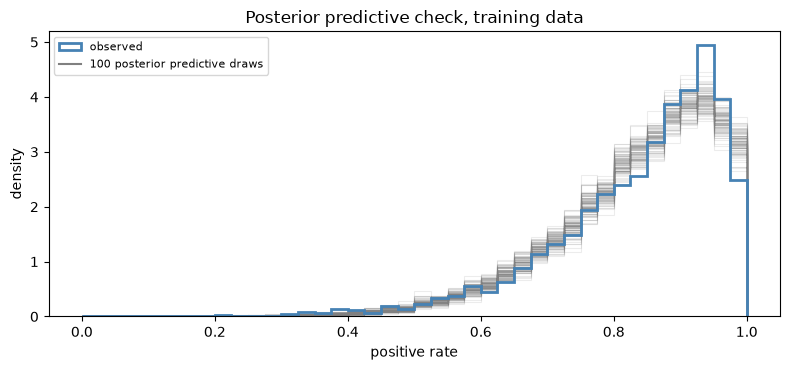

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, 1, 41)
for r in rep_rates[:100]:
    ax.hist(r, bins=bins, density=True, histtype="step", color="grey", alpha=0.15, linewidth=0.8)
ax.hist(obs, bins=bins, density=True, histtype="step", color="steelblue", linewidth=2, label="observed")
ax.plot([], [], color="grey", label="100 posterior predictive draws")
ax.set_xlabel("positive rate"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Posterior predictive check, training data")
plt.tight_layout()
save_fig(fig, "06_aq5_posterior_predictive")
plt.show()

### Interpretation: Posterior predictive check
**Author**: 
<!-- Compare observed and replicated rates. Cover whether the model reproduces the centre, the spread and the share of very high and very low rates, and, from the band table, whether it gets the spread right in every review-count band or misses at small or large counts. A share near 0 or 1 in the last column means the observed value sits outside what the model produces. -->

## 4. Prior sensitivity
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the model is refitted with wider priors: intercept Normal(0, 5), coefficients Normal(0, 2), and a log-scale SD of 2 on the concentration. Everything else is unchanged. Shifts are measured in posterior SDs of the main fit. The wide fit's convergence checks are printed too, since a sensitivity fit that did not converge cannot be compared.

In [8]:
WIDE_PRIORS = {"intercept": 5.0, "beta": 2.0, "phi_log_sd": 2.0}
with build_model(WIDE_PRIORS):
    idata_wide = pm.sample(**SAMPLE_KW)
wide_summary, wide_checks, wide_ok = diagnostics(idata_wide)
print(wide_checks.round(3).to_string())
print(f"wide-prior fit thresholds -> {'all met' if wide_ok else 'NOT MET'}\n")

sensitivity = pd.DataFrame({"mean_main": bayes_summary["mean"], "sd_main": bayes_summary["sd"],
                            "mean_wide": wide_summary["mean"], "sd_wide": wide_summary["sd"]}).astype(float)
sensitivity["shift_in_main_sds"] = (sensitivity["mean_wide"] - sensitivity["mean_main"]) / sensitivity["sd_main"]
sensitivity.to_csv(config.TABLES / "06_aq5_prior_sensitivity.csv")
print(f"largest shift: {sensitivity['shift_in_main_sds'].abs().max():.2f} posterior SDs "
      f"({sensitivity['shift_in_main_sds'].abs().idxmax()})")
sensitivity.round(3).sort_values("shift_in_main_sds", key=np.abs, ascending=False).head(12)

NUTS[numpyro]: [intercept, beta, phi]


max r_hat          1.004
min ess_bulk    2216.328
min ess_tail    2141.823
divergences        0.000
wide-prior fit thresholds -> all met

largest shift: 0.11 posterior SDs (beta[cat_coop])


,mean_main,sd_main,mean_wide,sd_wide,shift_in_main_sds
beta[cat_coop],-0.237,0.088,-0.247,0.090,-0.112
beta[cat_multiplayer],0.136,0.075,0.144,0.076,0.103
intercept,1.854,0.125,1.866,0.126,0.098
beta[flag_has_support_contact],-0.049,0.105,-0.056,0.106,-0.066
beta[flag_has_achievements],-0.107,0.068,-0.112,0.069,-0.065
beta[feature_log_achievements],0.028,0.028,0.030,0.028,0.063
beta[flag_free_to_play],0.250,0.058,0.254,0.058,0.063
beta[genre_strategy],-0.302,0.041,-0.304,0.041,-0.063
beta[flag_missing_genre],-0.077,0.233,-0.091,0.262,-0.058
beta[feature_log_audio_language_count],0.049,0.026,0.050,0.026,0.050


### Interpretation: Prior sensitivity
**Author**: 
<!-- Say whether the results depend on the priors: how far the largest posterior mean moved in posterior SDs, which parameters moved, and in particular whether phi moved, since phi sets the shrinkage in section 5. -->

## 5. Shrinkage by review count
*Code: Generated by AI Assistant*

*Written by AI Assistant*: given the model, each game's true rate has a posterior of its own, $\text{Beta}(\mu_i \phi + k_i,\ (1 - \mu_i) \phi + n_i - k_i)$. Its mean is a weighted average of the game's raw rate and the model's expectation $\mu_i$, with weight $w_i = n_i / (n_i + \phi)$ on the game's own reviews. A game with few reviews is pulled towards what is typical for games like it. A game with many keeps its own rate. The weight table gives $w$ at fixed review counts, including the two thresholds set in notebook 02.

Each game's posterior is drawn once per posterior draw of $\mu_i$ and $\phi$, so the interval includes uncertainty in the model as well as in the game's own reviews.

In [9]:
def flat(trace, name):
    a = np.asarray(trace.posterior[name])
    return a.reshape(a.shape[0] * a.shape[1], -1)

draws = {k: flat(idata, k) for k in ["intercept", "beta", "phi"]}
use = rng.choice(len(draws["phi"]), size=1000, replace=False)
phi_d = draws["phi"][use]                                                   # draws x 1
mu_train = expit(draws["intercept"][use] + draws["beta"][use] @ X_train.T)  # draws x games
p_post = rng.beta(mu_train * phi_d + k_train, (1 - mu_train) * phi_d + n_train - k_train)

train["model_expectation"] = mu_train.mean(0)
train["shrunk_rate"] = p_post.mean(0)
train["shrunk_low"], train["shrunk_high"] = np.quantile(p_post, [0.025, 0.975], axis=0)
train["shrunk_width"] = train["shrunk_high"] - train["shrunk_low"]
train["weight_own_reviews"] = (n_train / (n_train + phi_d)).mean(0)
train["shift"] = train["shrunk_rate"] - train["raw_rate"]

ref_n = sorted({MIN_REVIEWS, feature_spec["inclusion_thresholds"]["min_reviews_completion"], 25, 100, 200, 500, 1000, 5000})
w = ref_n / (ref_n + phi_d)                                                 # draws x reference counts
weight_table = pd.DataFrame({"reviews": ref_n, "weight_own_reviews": w.mean(0),
                             "weight_5%": np.quantile(w, 0.05, axis=0), "weight_95%": np.quantile(w, 0.95, axis=0)}).set_index("reviews")
weight_table.to_csv(config.TABLES / "06_aq5_shrinkage_weights.csv")

by_band = train.groupby("band", observed=True).agg(
    games=("n", "size"), median_abs_shift=("shift", lambda s: s.abs().median()), max_abs_shift=("shift", lambda s: s.abs().max()),
    median_wilson_width=("wilson_width", "median"), median_bayes_width=("shrunk_width", "median"))
by_band.to_csv(config.TABLES / "06_aq5_shrinkage_by_band.csv")
print(f"posterior mean phi = {phi_d.mean():.1f}")
display(weight_table.round(3))
by_band.round(4)

posterior mean phi = 10.2


,weight_own_reviews,weight_5%,weight_95%
reviews,,,
10,0.496,0.486,0.506
25,0.711,0.703,0.719
50,0.831,0.825,0.837
100,0.908,0.904,0.911
200,0.952,0.950,0.953
500,0.980,0.979,0.981
1000,0.990,0.990,0.990
5000,0.998,0.998,0.998


,games,median_abs_shift,max_abs_shift,median_wilson_width,median_bayes_width
band,,,,,
10-49,532,0.0233,0.3456,0.2588,0.2218
50-199,1007,0.0068,0.0805,0.1349,0.1276
200-999,1207,0.0016,0.0210,0.0639,0.0625
"1,000-9,999",993,0.0003,0.0037,0.0234,0.0234
"10,000+",376,0.0000,0.0004,0.0070,0.0069


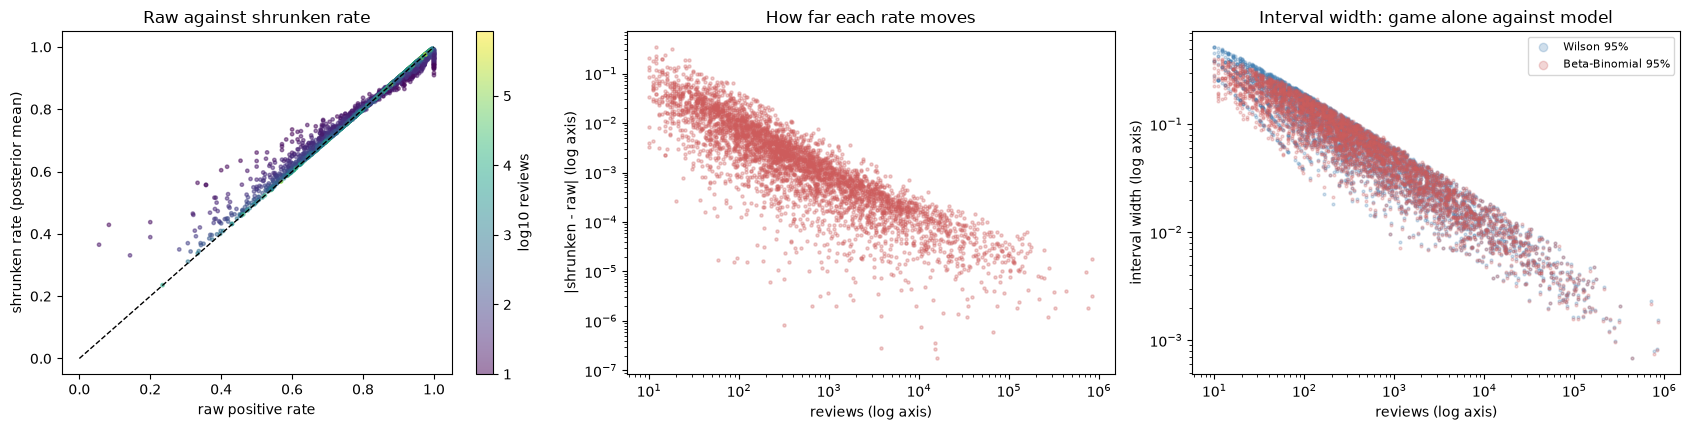

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sc = axes[0].scatter(train["raw_rate"], train["shrunk_rate"], c=np.log10(train["n"]), s=6, alpha=0.5, cmap="viridis")
axes[0].plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("raw positive rate"); axes[0].set_ylabel("shrunken rate (posterior mean)")
axes[0].set_title("Raw against shrunken rate"); fig.colorbar(sc, ax=axes[0], label="log10 reviews")
axes[1].scatter(train["n"], train["shift"].abs(), s=5, alpha=0.3, color="indianred")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("reviews (log axis)"); axes[1].set_ylabel("|shrunken - raw| (log axis)")
axes[1].set_title("How far each rate moves")
axes[2].scatter(train["n"], train["wilson_width"], s=4, alpha=0.25, color="steelblue", label="Wilson 95%")
axes[2].scatter(train["n"], train["shrunk_width"], s=4, alpha=0.25, color="indianred", label="Beta-Binomial 95%")
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xlabel("reviews (log axis)"); axes[2].set_ylabel("interval width (log axis)")
axes[2].set_title("Interval width: game alone against model"); axes[2].legend(fontsize=8, markerscale=3)
plt.tight_layout()
save_fig(fig, "06_aq5_shrinkage")
plt.show()

### Interpretation: Shrinkage by review count
**Author**: 
<!-- Describe how the weight on a game's own reviews changes with review count, using the weight table, and what that means at the two thresholds from notebook 02. Cover which games move most from raw to shrunken rate and in which direction, and how the Beta-Binomial interval compares with the Wilson interval at small and large review counts. Keep to what the numbers show; whether a studio should use shrunken rates is for AQ4. -->

## 6. Raw against shrunken rankings
*Code: Generated by AI Assistant*

*Written by AI Assistant*: three ways to rank games by reception: the raw rate, the shrunken rate from section 5, and the lower end of the Wilson interval, a common way to penalise small samples without a model. The table compares each ranking's top 50 with the others, and reports the median review count of the games in each. A Spearman correlation across all games measures how far the full orderings agree.

In [11]:
TOP = 50
rankings = {"raw rate": "raw_rate", "shrunken rate": "shrunk_rate", "Wilson lower bound": "wilson_low"}
tops = {name: set(train.nlargest(TOP, col)["steam_appid"]) for name, col in rankings.items()}
rows = []
for name, col in rankings.items():
    top = train.nlargest(TOP, col)
    rows.append({"ranking": name, f"median_reviews_top_{TOP}": top["n"].median(), f"min_reviews_top_{TOP}": top["n"].min(),
                 **{f"overlap_with_{o}": len(tops[name] & tops[o]) for o in rankings if o != name}})
rank_table = pd.DataFrame(rows).set_index("ranking")
rank_table.to_csv(config.TABLES / "06_aq5_ranking_overlap.csv")
rho = train[list(rankings.values())].corr(method="spearman")
rho.index = rho.columns = list(rankings)
display(rank_table)
display(rho.round(3))
train.nlargest(15, "shrunk_rate")[["steam_name", "n", "raw_rate", "shrunk_rate", "shrunk_low", "shrunk_high", "wilson_low"]].round(3)

,median_reviews_top_50,min_reviews_top_50,overlap_with_shrunken rate,overlap_with_Wilson lower bound,overlap_with_raw rate
ranking,,,,,
raw rate,30.0,10,6.0,1.0,NaN
shrunken rate,686.5,58,NaN,33.0,6.0
Wilson lower bound,3303.5,167,33.0,NaN,1.0


,raw rate,shrunken rate,Wilson lower bound
raw rate,1.000,0.995,0.914
shrunken rate,0.995,1.000,0.934
Wilson lower bound,0.914,0.934,1.000


,steam_name,n,raw_rate,shrunk_rate,shrunk_low,shrunk_high,wilson_low
3030,Beastieball,1168,0.996,0.995,0.991,0.998,0.990
2719,Seal World,899,0.996,0.994,0.989,0.998,0.989
4069,Monster Prom 4: Monster Con,1444,0.993,0.992,0.987,0.996,0.987
448,Dialtown: Phone Dating Sim,1954,0.993,0.992,0.988,0.996,0.988
625,The Upturned,2364,0.993,0.992,0.989,0.995,0.989
3414,Once Upon a Jester,208,1.000,0.992,0.978,0.999,0.982
2102,Duck Detective: The Ghost of Glamping,909,0.992,0.991,0.984,0.996,0.984
1807,Don't Escape Trilogy,538,0.994,0.991,0.981,0.997,0.984
991,her tears were my light,599,0.993,0.991,0.983,0.997,0.983
2411,Moss: Book II,612,0.993,0.991,0.982,0.997,0.983


### Interpretation: Raw against shrunken rankings
**Author**: 
<!-- Compare the three rankings: how much their top 50 lists overlap, how the review counts of the top games differ between them, and how strongly the full orderings agree. Describe which kind of game drops out of the top when moving from the raw rate to the shrunken rate or the Wilson lower bound. -->

## 7. Validation: calibration and interval coverage
*Code: Generated by AI Assistant, adapted from Sheen Fernando's Beta-Binomial model in `notebooks/archive/03_aq2_reception_models.ipynb`*

*Written by AI Assistant*: the model is checked on validation games it never saw. Calibration follows Sheen's decile method: games are grouped by predicted rate, and the mean predicted rate in each group is compared with the observed rate. Coverage asks how often a game's observed rate falls inside its 90% posterior predictive interval, which allows for both the spread of true rates and binomial noise at the game's own review count. Coverage is reported by review-count band, since a model can be well calibrated on average and still be over- or under-confident at small counts.

validation games: 1,029; MAE 0.0950, RMSE 0.1255, mean bias -0.0046
overall 90% coverage: 0.920
Bayesian model converged: True


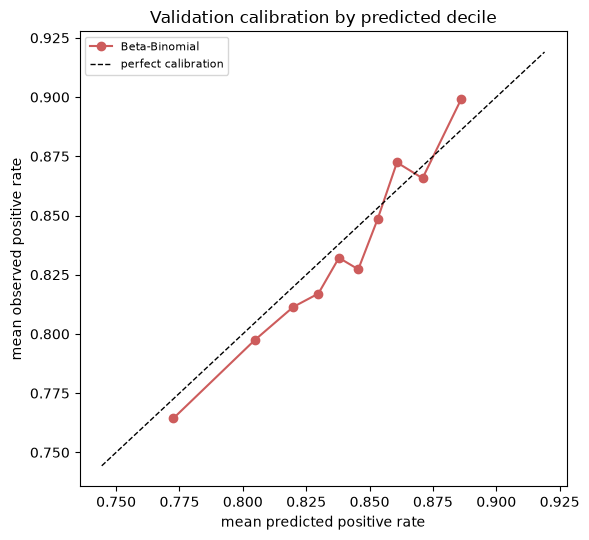

,games,mean_predicted,mean_observed
decile,,,
0,103,0.7725,0.7643
1,103,0.8047,0.7974
2,103,0.8199,0.8114
3,103,0.8298,0.8170
4,103,0.8379,0.8321
5,102,0.8455,0.8273
6,103,0.8532,0.8485
7,103,0.8608,0.8724
8,103,0.8709,0.8657


,games,coverage_90,median_interval_width
band,,,
10-49,134,0.918,0.389
50-199,267,0.899,0.362
200-999,314,0.927,0.350
"1,000-9,999",233,0.936,0.352
"10,000+",81,0.926,0.361


In [12]:
mu_v = expit(draws["intercept"][use] + draws["beta"][use] @ X_val.T)       # draws x validation games
p_v = rng.beta(mu_v * phi_d, (1 - mu_v) * phi_d)
k_rep = rng.binomial(n_val[None, :], p_v)
val["predicted_rate"] = mu_v.mean(0)
val["pp_low"], val["pp_high"] = np.quantile(k_rep / n_val, [0.05, 0.95], axis=0)
val["covered_90"] = (val["raw_rate"] >= val["pp_low"]) & (val["raw_rate"] <= val["pp_high"])
val["pp_width"] = val["pp_high"] - val["pp_low"]

val["decile"] = pd.qcut(val["predicted_rate"], 10, labels=False, duplicates="drop")
calibration = val.groupby("decile").agg(games=("n", "size"), mean_predicted=("predicted_rate", "mean"),
                                        mean_observed=("raw_rate", "mean"))
coverage = val.groupby("band", observed=True).agg(games=("n", "size"), coverage_90=("covered_90", "mean"),
                                                  median_interval_width=("pp_width", "median"))
calibration.to_csv(config.TABLES / "06_aq5_validation_calibration.csv")
coverage.to_csv(config.TABLES / "06_aq5_validation_coverage.csv")

err = val["raw_rate"] - val["predicted_rate"]
print(f"validation games: {len(val):,}; MAE {err.abs().mean():.4f}, RMSE {np.sqrt((err ** 2).mean()):.4f}, mean bias {err.mean():.4f}")
print(f"overall 90% coverage: {val['covered_90'].mean():.3f}")
print("Bayesian model converged:", bayes_ok)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(calibration["mean_predicted"], calibration["mean_observed"], marker="o", color="indianred", label="Beta-Binomial")
lo, hi = calibration[["mean_predicted", "mean_observed"]].min().min() - 0.02, calibration[["mean_predicted", "mean_observed"]].max().max() + 0.02
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=1, label="perfect calibration")
ax.set_xlabel("mean predicted positive rate"); ax.set_ylabel("mean observed positive rate")
ax.set_title("Validation calibration by predicted decile"); ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "06_aq5_validation_calibration")
plt.show()
display(calibration.round(4))
coverage.round(3)

### Interpretation: Validation calibration and coverage
**Author**: 
<!-- Say whether predicted rates match observed rates across the deciles, and where they depart. Then describe 90% interval coverage by review-count band: whether the model is over-confident (coverage well below 90%) or under-confident (well above) at small and large review counts, and how interval width shrinks with review count. -->

## Save for later stages
*Code: Generated by AI Assistant*

*Written by AI Assistant*: per-game raw rates, Wilson intervals, shrunken rates and shrinkage weights for the training reception sample are saved for AQ4. No rows are filtered beyond the reception sample in section 1.

In [13]:
cols = ["steam_appid", "steam_name", "n", "k", "band", "raw_rate", "wilson_low", "wilson_high",
        "model_expectation", "shrunk_rate", "shrunk_low", "shrunk_high", "weight_own_reviews"]
train[cols].to_parquet(config.INTERIM / "06_aq5_shrinkage.parquet", index=False)
print(f"rows out: {len(train):,} games -> data/interim/06_aq5_shrinkage.parquet")
print(f"figures: {sorted(p.name for p in config.FIGURES.glob('06_aq5_*.png'))}")
print(f"tables : {sorted(p.name for p in config.TABLES.glob('06_aq5_*.csv'))}")

rows out: 4,115 games -> data/interim/06_aq5_shrinkage.parquet
figures: ['06_aq5_posterior_predictive.png', '06_aq5_raw_rate_and_wilson.png', '06_aq5_shrinkage.png', '06_aq5_validation_calibration.png']
tables : ['06_aq5_bayes_summary.csv', '06_aq5_posterior_predictive.csv', '06_aq5_prior_sensitivity.csv', '06_aq5_ranking_overlap.csv', '06_aq5_raw_rate_by_band.csv', '06_aq5_shrinkage_by_band.csv', '06_aq5_shrinkage_weights.csv', '06_aq5_validation_calibration.csv', '06_aq5_validation_coverage.csv']
